# Customer Segmentation & Marketing Analytics

## 01 — Data Preparation and Exploratory Data Analysis

### Project Objective

The objective of this project is to analyze customer purchasing behaviour,
develop meaningful customer segments, and translate those segments into
actionable marketing strategies.

The project will use transactional retail data to examine customer value,
purchase frequency, recency, and spending behaviour.

### Core Approach

1. Data preparation and exploratory analysis
2. Customer-level behavioural analysis
3. RFM analysis
4. RFM-based customer segmentation
5. K-Means clustering
6. Marketing analytics and segment profiling
7. Marketing recommendations

> **Project principle: Core fundamentals > unnecessary depth**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
df = pd.read_excel("../data/Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [4]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
df = pd.read_excel("../data/Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [6]:
df.shape

(541909, 8)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386048,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


In [10]:
# Missing CustomerID percentage
df["CustomerID"].isna().mean() * 100

np.float64(24.926694334288598)

In [11]:
# Number of unique customers
df["CustomerID"].nunique()

4372

In [12]:
# Number of unique invoices
df["InvoiceNo"].nunique()

25900

In [13]:
# Transactions with negative or zero quantities
(df["Quantity"] <= 0).sum()

np.int64(10624)

In [14]:
# Transactions with negative or zero prices
(df["UnitPrice"] <= 0).sum()

np.int64(2517)

In [15]:
# Look at some rows with negative quantities
df[df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,"14,527.00",United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,"15,311.00",United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,"17,548.00",United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,"17,897.00",United Kingdom


In [16]:
df[df["InvoiceNo"].astype(str).str.startswith("C")].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,"14,527.00",United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,"15,311.00",United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,"17,548.00",United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,"17,897.00",United Kingdom


In [17]:
# Country distribution
df["Country"].value_counts().head(15)

Country
United Kingdom     495478
Germany              9495
France               8557
EIRE                 8196
Spain                2533
Netherlands          2371
Belgium              2069
Switzerland          2002
Portugal             1519
Australia            1259
Norway               1086
Italy                 803
Channel Islands       758
Finland               695
Cyprus                622
Name: count, dtype: int64

In [18]:
df_clean = df.copy()

df_clean = df_clean[
    df_clean["CustomerID"].notna()
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
    & (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

df_clean.shape

(397884, 8)

In [19]:
print("Original rows:", df.shape[0])
print("Clean rows:", df_clean.shape[0])
print("Rows removed:", df.shape[0] - df_clean.shape[0])

print("\nMissing CustomerIDs:")
print(df_clean["CustomerID"].isna().sum())

print("\nNon-positive quantities:")
print((df_clean["Quantity"] <= 0).sum())

print("\nNon-positive prices:")
print((df_clean["UnitPrice"] <= 0).sum())

print("\nCancellation invoices:")
print(
    df_clean["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
    .sum()
)

Original rows: 541909
Clean rows: 397884
Rows removed: 144025

Missing CustomerIDs:
0

Non-positive quantities:
0

Non-positive prices:
0

Cancellation invoices:
0


In [20]:
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34


In [21]:
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Unique invoices:", df_clean["InvoiceNo"].nunique())
print("Countries:", df_clean["Country"].nunique())
print("Total revenue:", df_clean["Revenue"].sum())

Unique customers: 4338
Unique invoices: 18532
Countries: 37
Total revenue: 8911407.904


In [22]:
country_summary = (
    df_clean.groupby("Country")
    .agg(
        Customers=("CustomerID", "nunique"),
        Invoices=("InvoiceNo", "nunique"),
        Revenue=("Revenue", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

country_summary.head(15)

,Customers,Invoices,Revenue
Country,,,
United Kingdom,3920,16646,"7,308,391.55"
Netherlands,9,94,"285,446.34"
EIRE,3,260,"265,545.90"
Germany,94,457,"228,867.14"
France,87,389,"209,024.05"
Australia,9,57,"138,521.31"
Spain,30,90,"61,577.11"
Switzerland,21,51,"56,443.95"
Belgium,25,98,"41,196.34"


In [23]:
uk_customer_share = (
    country_summary.loc["United Kingdom", "Customers"]
    / country_summary["Customers"].sum()
    * 100
)

uk_revenue_share = (
    country_summary.loc["United Kingdom", "Revenue"]
    / country_summary["Revenue"].sum()
    * 100
)

print("UK customer share:", round(uk_customer_share, 2), "%")
print("UK revenue share:", round(uk_revenue_share, 2), "%")

UK customer share: 90.2 %
UK revenue share: 82.01 %


In [24]:
country_summary.head(10)

,Customers,Invoices,Revenue
Country,,,
United Kingdom,3920,16646,"7,308,391.55"
Netherlands,9,94,"285,446.34"
EIRE,3,260,"265,545.90"
Germany,94,457,"228,867.14"
France,87,389,"209,024.05"
Australia,9,57,"138,521.31"
Spain,30,90,"61,577.11"
Switzerland,21,51,"56,443.95"
Belgium,25,98,"41,196.34"


In [25]:
df_uk = df_clean[
    df_clean["Country"] == "United Kingdom"
].copy()

df_uk.shape

(354321, 9)

In [26]:
df_uk["CustomerID"].nunique()

3920

In [27]:
customer_summary = (
    df_uk.groupby("CustomerID")
    .agg(
        Orders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        TotalRevenue=("Revenue", "sum"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
    .reset_index()
)

customer_summary.head()

,CustomerID,Orders,TotalQuantity,TotalRevenue,FirstPurchase,LastPurchase
0,"12,346.00",1,74215,"77,183.60",2011-01-18 10:01:00,2011-01-18 10:01:00
1,"12,747.00",11,1275,"4,196.01",2010-12-05 15:38:00,2011-12-07 14:34:00
2,"12,748.00",209,25747,"33,719.73",2010-12-01 12:48:00,2011-12-09 12:20:00
3,"12,749.00",5,1471,"4,090.88",2011-05-10 15:25:00,2011-12-06 09:56:00
4,"12,820.00",4,722,942.34,2011-01-17 12:34:00,2011-12-06 15:12:00


In [28]:
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)
df_uk["CustomerID"] = df_uk["CustomerID"].astype(int)

In [29]:
customer_summary = (
    df_uk.groupby("CustomerID")
    .agg(
        Orders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        TotalRevenue=("Revenue", "sum"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
    .reset_index()
)

customer_summary.head()

,CustomerID,Orders,TotalQuantity,TotalRevenue,FirstPurchase,LastPurchase
0,12346,1,74215,"77,183.60",2011-01-18 10:01:00,2011-01-18 10:01:00
1,12747,11,1275,"4,196.01",2010-12-05 15:38:00,2011-12-07 14:34:00
2,12748,209,25747,"33,719.73",2010-12-01 12:48:00,2011-12-09 12:20:00
3,12749,5,1471,"4,090.88",2011-05-10 15:25:00,2011-12-06 09:56:00
4,12820,4,722,942.34,2011-01-17 12:34:00,2011-12-06 15:12:00


In [30]:
customer_summary["AverageOrderValue"] = (
    customer_summary["TotalRevenue"] / customer_summary["Orders"]
)

customer_summary["CustomerLifespanDays"] = (
    customer_summary["LastPurchase"] - customer_summary["FirstPurchase"]
).dt.days

customer_summary.head()

,CustomerID,Orders,TotalQuantity,TotalRevenue,FirstPurchase,LastPurchase,AverageOrderValue,CustomerLifespanDays
0,12346,1,74215,"77,183.60",2011-01-18 10:01:00,2011-01-18 10:01:00,"77,183.60",0
1,12747,11,1275,"4,196.01",2010-12-05 15:38:00,2011-12-07 14:34:00,381.46,366
2,12748,209,25747,"33,719.73",2010-12-01 12:48:00,2011-12-09 12:20:00,161.34,372
3,12749,5,1471,"4,090.88",2011-05-10 15:25:00,2011-12-06 09:56:00,818.18,209
4,12820,4,722,942.34,2011-01-17 12:34:00,2011-12-06 15:12:00,235.59,323


In [31]:
customer_summary[
    [
        "Orders",
        "TotalQuantity",
        "TotalRevenue",
        "AverageOrderValue",
        "CustomerLifespanDays"
    ]
].describe()

,Orders,TotalQuantity,TotalRevenue,AverageOrderValue,CustomerLifespanDays
count,"3,920.00","3,920.00","3,920.00","3,920.00","3,920.00"
mean,4.25,"1,085.90","1,864.39",393.33,131.02
std,7.20,"3,737.51","7,482.82","1,869.97",132.27
min,1.00,1.00,3.75,3.45,0.00
25%,1.00,154.00,300.28,174.40,0.00
50%,2.00,365.00,652.28,281.62,93.00
75%,5.00,950.25,"1,576.59",409.69,252.00
max,209.00,"80,997.00","259,657.30","84,236.25",373.00


In [32]:
customer_summary.sort_values(
    "TotalRevenue",
    ascending=False
).head(10)

,CustomerID,Orders,TotalQuantity,TotalRevenue,FirstPurchase,LastPurchase,AverageOrderValue,CustomerLifespanDays
3783,18102,60,64124,"259,657.30",2010-12-07 16:42:00,2011-12-09 11:50:00,"4,327.62",366
3314,17450,46,69993,"194,550.79",2010-12-07 09:23:00,2011-12-01 13:29:00,"4,229.36",359
2598,16446,2,80997,"168,472.50",2011-05-18 09:52:00,2011-12-09 09:15:00,"84,236.25",204
3356,17511,31,64549,"91,062.38",2010-12-01 10:19:00,2011-12-07 10:12:00,"2,937.50",370
2294,16029,63,40208,"81,024.84",2010-12-01 09:57:00,2011-11-01 10:27:00,"1,286.11",335
0,12346,1,74215,"77,183.60",2011-01-18 10:01:00,2011-01-18 10:01:00,"77,183.60",0
2766,16684,28,50255,"66,653.56",2010-12-16 17:34:00,2011-12-05 14:06:00,"2,380.48",353
902,14096,17,16352,"65,164.79",2011-08-30 10:49:00,2011-12-05 17:17:00,"3,833.22",97
620,13694,50,63312,"65,039.62",2010-12-01 12:12:00,2011-12-06 09:32:00,"1,300.79",369
1771,15311,91,38194,"60,767.90",2010-12-01 09:41:00,2011-12-09 12:00:00,667.78,373


In [33]:
customer_summary.sort_values(
    "Orders",
    ascending=False
).head(10)

,CustomerID,Orders,TotalQuantity,TotalRevenue,FirstPurchase,LastPurchase,AverageOrderValue,CustomerLifespanDays
2,12748,209,25747,"33,719.73",2010-12-01 12:48:00,2011-12-09 12:20:00,161.34,372
3593,17841,124,23071,"40,991.57",2010-12-01 14:41:00,2011-12-08 12:07:00,330.58,371
191,13089,97,31070,"58,825.83",2010-12-05 10:27:00,2011-12-07 09:02:00,606.45,366
1267,14606,93,6224,"12,156.65",2010-12-01 16:57:00,2011-12-08 19:28:00,130.72,372
1771,15311,91,38194,"60,767.90",2010-12-01 09:41:00,2011-12-09 12:00:00,667.78,373
110,12971,86,9289,"11,189.91",2010-12-02 16:42:00,2011-12-06 12:20:00,130.12,368
2294,16029,63,40208,"81,024.84",2010-12-01 09:57:00,2011-11-01 10:27:00,"1,286.11",335
424,13408,62,16232,"28,117.04",2010-12-01 10:39:00,2011-12-08 09:05:00,453.50,371
3783,18102,60,64124,"259,657.30",2010-12-07 16:42:00,2011-12-09 11:50:00,"4,327.62",366
693,13798,57,23948,"37,153.85",2010-12-02 17:24:00,2011-12-08 15:51:00,651.82,370


In [34]:
reference_date = df_uk["InvoiceDate"].max() + pd.Timedelta(days=1)

reference_date

Timestamp('2011-12-10 12:49:00')

In [35]:
rfm = (
    df_uk.groupby("CustomerID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (reference_date - x.max()).days
        ),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,"77,183.60"
1,12747,2,11,"4,196.01"
2,12748,1,209,"33,719.73"
3,12749,4,5,"4,090.88"
4,12820,3,4,942.34


In [36]:
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,"3,920.00","3,920.00","3,920.00","3,920.00"
mean,"15,562.06",92.21,4.25,"1,864.39"
std,"1,576.59",99.53,7.20,"7,482.82"
min,"12,346.00",1.00,1.00,3.75
25%,"14,208.75",18.00,1.00,300.28
50%,"15,569.50",51.00,2.00,652.28
75%,"16,913.25",143.00,5.00,"1,576.59"
max,"18,287.00",374.00,209.00,"259,657.30"


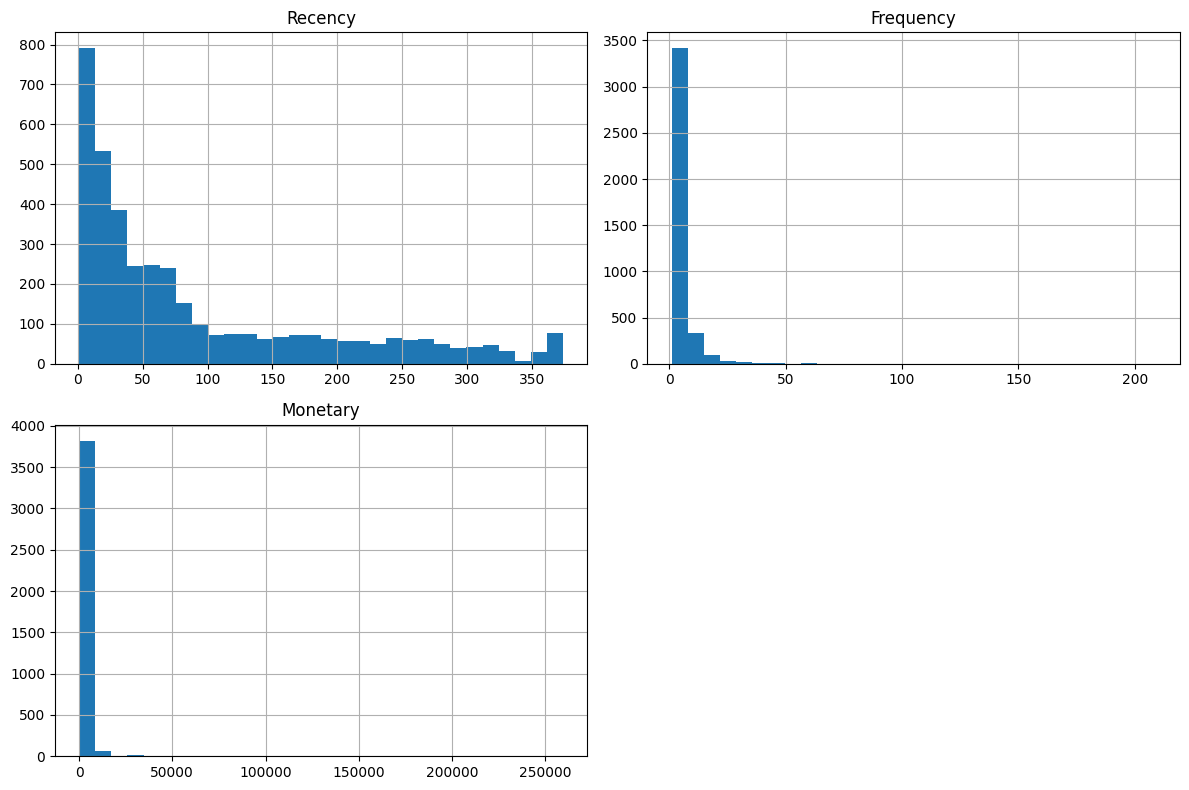

In [37]:
rfm[["Recency", "Frequency", "Monetary"]].hist(
    bins=30,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

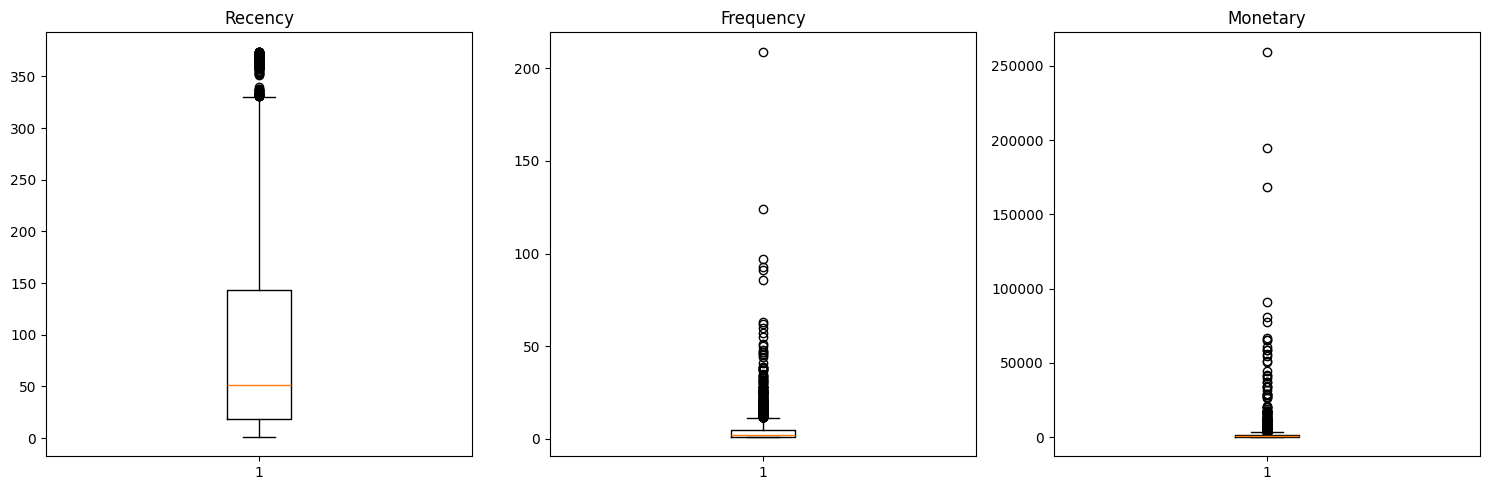

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].boxplot(rfm["Recency"])
axes[0].set_title("Recency")

axes[1].boxplot(rfm["Frequency"])
axes[1].set_title("Frequency")

axes[2].boxplot(rfm["Monetary"])
axes[2].set_title("Monetary")

plt.tight_layout()
plt.show()

In [39]:
rfm[["Recency", "Frequency", "Monetary"]].skew()

Recency      1.25
Frequency   10.75
Monetary    20.20
dtype: float64

In [40]:
rfm_transformed = rfm.copy()

rfm_transformed["Recency"] = np.log1p(rfm_transformed["Recency"])
rfm_transformed["Frequency"] = np.log1p(rfm_transformed["Frequency"])
rfm_transformed["Monetary"] = np.log1p(rfm_transformed["Monetary"])

rfm_transformed[["Recency", "Frequency", "Monetary"]].skew()

Recency     -0.38
Frequency    1.18
Monetary     0.37
dtype: float64

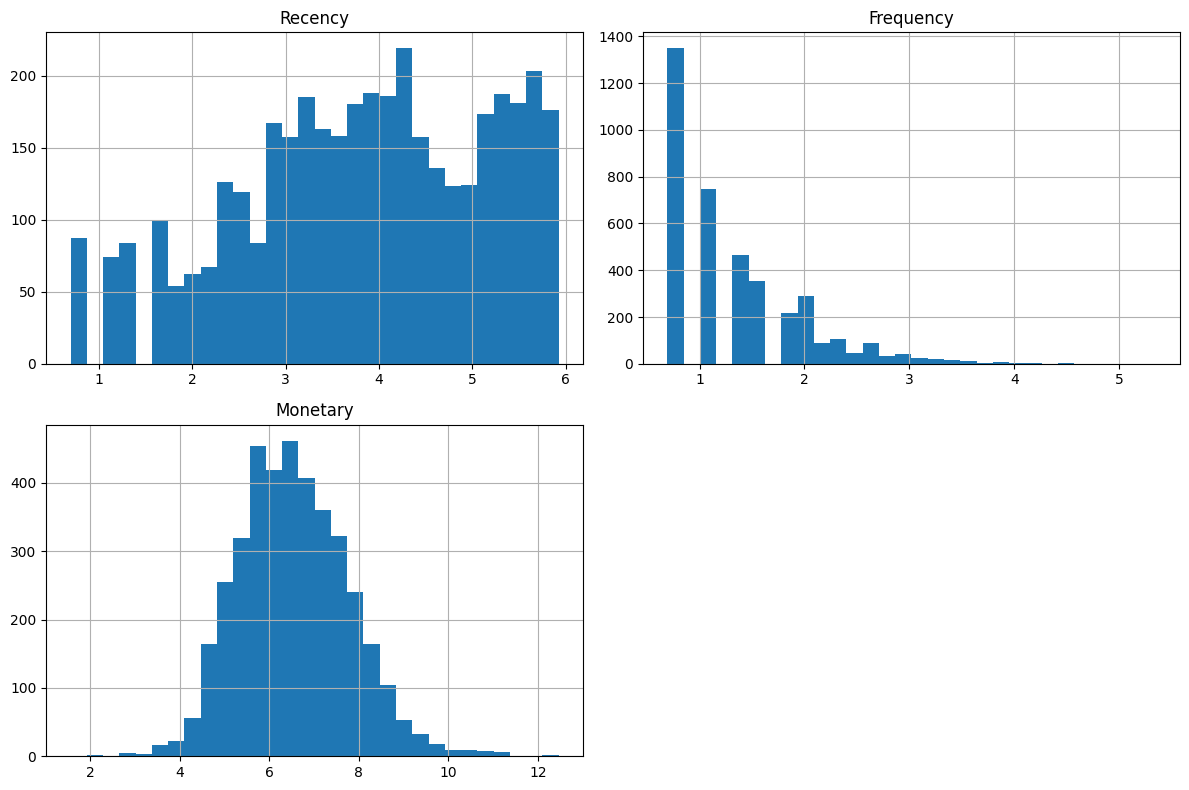

In [41]:
rfm_transformed[
    ["Recency", "Frequency", "Monetary"]
].hist(
    bins=30,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

In [42]:
from sklearn.preprocessing import StandardScaler

In [43]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_transformed[["Recency", "Frequency", "Monetary"]]
)

In [44]:
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm_transformed.index
)

rfm_scaled.head()

,Recency,Frequency,Monetary
0,1.46,-0.96,3.79
1,-2.04,1.67,1.44
2,-2.34,5.86,3.12
3,-1.65,0.65,1.42
4,-1.82,0.39,0.24


In [45]:
rfm_scaled.mean()

Recency      0.00
Frequency    0.00
Monetary    -0.00
dtype: float64

In [46]:
rfm_scaled.std()

Recency     1.00
Frequency   1.00
Monetary    1.00
dtype: float64

In [47]:
from sklearn.cluster import KMeans

inertia = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

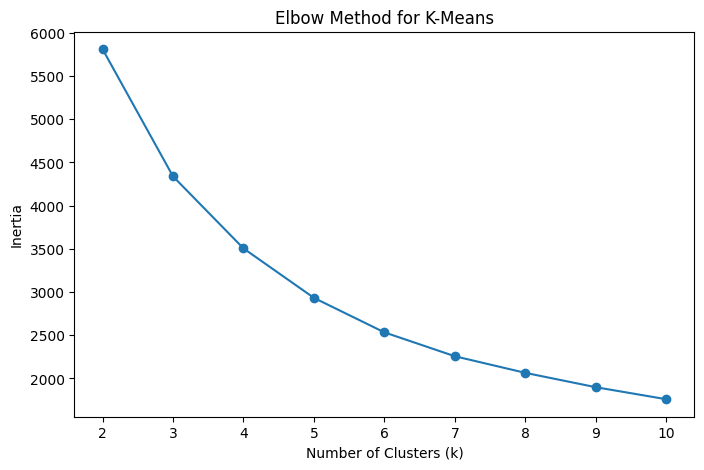

In [48]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")

plt.show()

In [49]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(rfm_scaled)
    
    score = silhouette_score(
        rfm_scaled,
        labels
    )
    
    silhouette_scores.append(score)

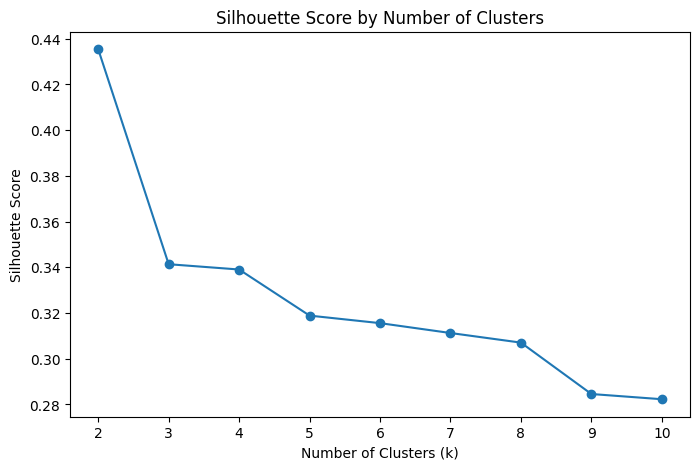

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")

plt.show()

In [51]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,"77,183.60",2
1,12747,2,11,"4,196.01",1
2,12748,1,209,"33,719.73",1
3,12749,4,5,"4,090.88",1
4,12820,3,4,942.34,3


In [52]:
rfm["Cluster"].value_counts().sort_index()

Cluster
0    1461
1     632
2    1051
3     776
Name: count, dtype: int64

In [53]:
cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        Customers=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean")
    )
    .round(2)
)

cluster_profile

,Customers,AvgRecency,AvgFrequency,AvgMonetary
Cluster,,,,
0,1461,182.84,1.33,331.77
1,632,11.56,13.68,"7,251.41"
2,1051,68.49,4.23,"1,743.95"
3,776,19.37,2.08,525.64


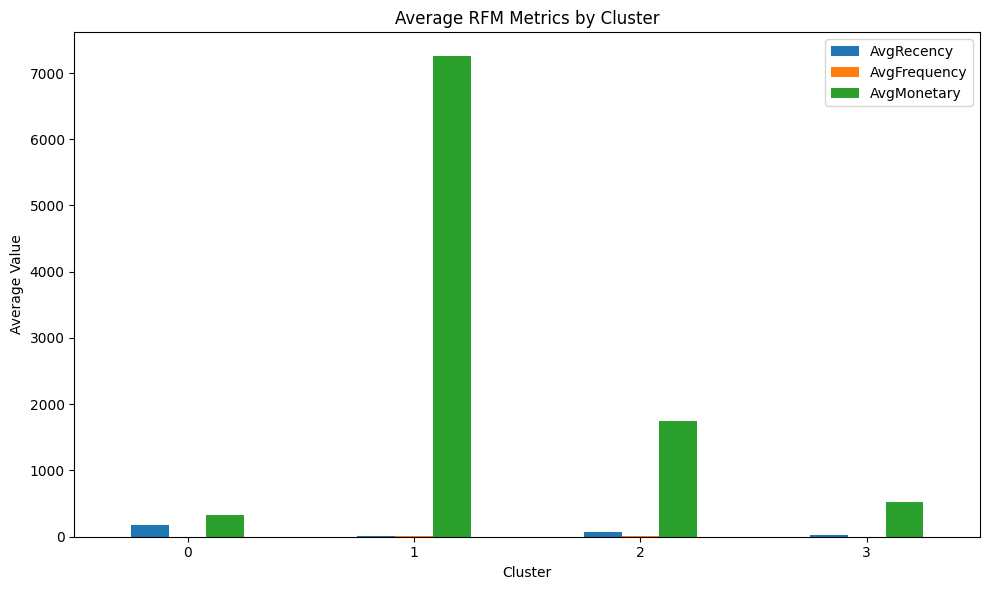

In [54]:
cluster_profile[
    ["AvgRecency", "AvgFrequency", "AvgMonetary"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average RFM Metrics by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [55]:
rfm_scaled_profile = rfm_scaled.copy()
rfm_scaled_profile["Cluster"] = rfm["Cluster"]

scaled_cluster_profile = (
    rfm_scaled_profile
    .groupby("Cluster")
    .mean()
)

scaled_cluster_profile

,Recency,Frequency,Monetary
Cluster,,,
0,0.90,-0.78,-0.79
1,-1.28,1.67,1.42
2,0.11,0.37,0.54
3,-0.79,-0.40,-0.40


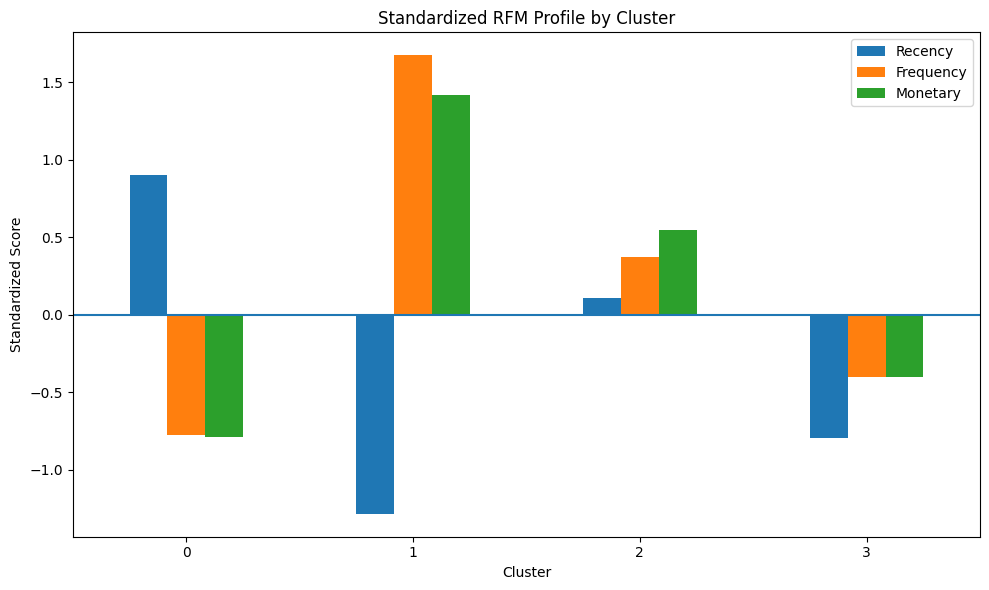

In [56]:
scaled_cluster_profile.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Standardized RFM Profile by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Standardized Score")
plt.axhline(0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:
segment_map = {
    0: "Inactive Low-Value",
    1: "High-Value Loyal",
    2: "Regular Mid-Value",
    3: "Recent Low-Engagement"
}

rfm["Segment"] = rfm["Cluster"].map(segment_map)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,"77,183.60",2,Regular Mid-Value
1,12747,2,11,"4,196.01",1,High-Value Loyal
2,12748,1,209,"33,719.73",1,High-Value Loyal
3,12749,4,5,"4,090.88",1,High-Value Loyal
4,12820,3,4,942.34,3,Recent Low-Engagement


In [58]:
segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean")
    )
    .round(2)
    .sort_values("AvgMonetary", ascending=False)
)

segment_summary

,Customers,AvgRecency,AvgFrequency,AvgMonetary
Segment,,,,
High-Value Loyal,632,11.56,13.68,"7,251.41"
Regular Mid-Value,1051,68.49,4.23,"1,743.95"
Recent Low-Engagement,776,19.37,2.08,525.64
Inactive Low-Value,1461,182.84,1.33,331.77


In [59]:
marketing_strategy_map = {
    "High-Value Loyal": "Retention, VIP rewards, loyalty benefits, early access, cross-sell premium products",
    "Regular Mid-Value": "Encourage repeat purchases, personalized recommendations, bundles, loyalty incentives",
    "Recent Low-Engagement": "Welcome campaigns, onboarding offers, second-purchase incentives, product discovery",
    "Inactive Low-Value": "Low-cost reactivation campaigns, limited-time offers, automated win-back emails"
}

rfm["MarketingStrategy"] = rfm["Segment"].map(marketing_strategy_map)

In [60]:
segment_strategy_summary = (
    rfm.groupby(["Segment", "MarketingStrategy"])
    .agg(
        Customers=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean")
    )
    .round(2)
    .reset_index()
)

segment_strategy_summary

,Segment,MarketingStrategy,Customers,AvgRecency,AvgFrequency,AvgMonetary
0,High-Value Loyal,"Retention, VIP rewards, loyalty benefits, earl...",632,11.56,13.68,"7,251.41"
1,Inactive Low-Value,"Low-cost reactivation campaigns, limited-time ...",1461,182.84,1.33,331.77
2,Recent Low-Engagement,"Welcome campaigns, onboarding offers, second-p...",776,19.37,2.08,525.64
3,Regular Mid-Value,"Encourage repeat purchases, personalized recom...",1051,68.49,4.23,"1,743.95"


In [61]:
segment_revenue = (
    rfm.groupby("Segment")
    .agg(
        Customers=("CustomerID", "count"),
        TotalRevenue=("Monetary", "sum")
    )
)

segment_revenue["RevenueSharePct"] = (
    segment_revenue["TotalRevenue"]
    / segment_revenue["TotalRevenue"].sum()
    * 100
)

segment_revenue["CustomerSharePct"] = (
    segment_revenue["Customers"]
    / segment_revenue["Customers"].sum()
    * 100
)

segment_revenue.round(2).sort_values(
    "RevenueSharePct",
    ascending=False
)

,Customers,TotalRevenue,RevenueSharePct,CustomerSharePct
Segment,,,,
High-Value Loyal,632,"4,582,893.51",62.71,16.12
Regular Mid-Value,1051,"1,832,893.04",25.08,26.81
Inactive Low-Value,1461,"484,708.99",6.63,37.27
Recent Low-Engagement,776,"407,896.01",5.58,19.80


In [62]:
customer_segments = rfm[
    ["CustomerID", "Segment"]
]

df_uk_segmented = df_uk.merge(
    customer_segments,
    on="CustomerID",
    how="left"
)

In [63]:
segment_business = (
    df_uk_segmented.groupby("Segment")
    .agg(
        Customers=("CustomerID", "nunique"),
        Orders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        TotalRevenue=("Revenue", "sum")
    )
)

segment_business["CustomerSharePct"] = (
    segment_business["Customers"]
    / segment_business["Customers"].sum()
    * 100
)

segment_business["QuantitySharePct"] = (
    segment_business["TotalQuantity"]
    / segment_business["TotalQuantity"].sum()
    * 100
)

segment_business["RevenueSharePct"] = (
    segment_business["TotalRevenue"]
    / segment_business["TotalRevenue"].sum()
    * 100
)

segment_business["AvgUnitsPerOrder"] = (
    segment_business["TotalQuantity"]
    / segment_business["Orders"]
)

segment_business["RevenuePerUnit"] = (
    segment_business["TotalRevenue"]
    / segment_business["TotalQuantity"]
)

segment_business.round(2)

,Customers,Orders,TotalQuantity,TotalRevenue,CustomerSharePct,QuantitySharePct,RevenueSharePct,AvgUnitsPerOrder,RevenuePerUnit
Segment,,,,,,,,,
High-Value Loyal,632,8646,2570653,"4,582,893.51",16.12,60.39,62.71,297.32,1.78
Inactive Low-Value,1461,1938,298994,"484,708.99",37.27,7.02,6.63,154.28,1.62
Recent Low-Engagement,776,1612,256727,"407,896.01",19.80,6.03,5.58,159.26,1.59
Regular Mid-Value,1051,4450,1130366,"1,832,893.04",26.81,26.55,25.08,254.01,1.62


In [64]:
segment_product_breadth = (
    df_uk_segmented.groupby("Segment")
    .agg(
        UniqueProducts=("StockCode", "nunique")
    )
)

segment_product_breadth

,UniqueProducts
Segment,
High-Value Loyal,3438
Inactive Low-Value,3107
Recent Low-Engagement,2966
Regular Mid-Value,3260


In [65]:
customer_product_breadth = (
    df_uk_segmented.groupby(
        ["CustomerID", "Segment"]
    )
    .agg(
        UniqueProducts=("StockCode", "nunique")
    )
    .reset_index()
)

customer_product_breadth.groupby("Segment")[
    "UniqueProducts"
].mean().round(2)

Segment
High-Value Loyal        152.82
Inactive Low-Value       21.92
Recent Low-Engagement    41.89
Regular Mid-Value        73.21
Name: UniqueProducts, dtype: float64

In [66]:
customer_product_breadth.groupby("Segment")[
    "UniqueProducts"
].agg(["mean", "median", "min", "max"]).round(2)

,mean,median,min,max
Segment,,,,
High-Value Loyal,152.82,117.00,3,1768
Inactive Low-Value,21.92,16.00,1,155
Recent Low-Engagement,41.89,30.00,1,313
Regular Mid-Value,73.21,60.00,1,421


In [67]:
segment_business = (
    df_uk_segmented.groupby("Segment")
    .agg(
        Customers=("CustomerID", "nunique"),
        Orders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        TotalRevenue=("Revenue", "sum")
    )
)

segment_business["CustomerSharePct"] = (
    segment_business["Customers"]
    / segment_business["Customers"].sum()
    * 100
)

segment_business["QuantitySharePct"] = (
    segment_business["TotalQuantity"]
    / segment_business["TotalQuantity"].sum()
    * 100
)

segment_business["RevenueSharePct"] = (
    segment_business["TotalRevenue"]
    / segment_business["TotalRevenue"].sum()
    * 100
)

segment_business["AvgUnitsPerOrder"] = (
    segment_business["TotalQuantity"]
    / segment_business["Orders"]
)

segment_business["RevenuePerUnit"] = (
    segment_business["TotalRevenue"]
    / segment_business["TotalQuantity"]
)

segment_business.round(2).sort_values(
    "RevenueSharePct",
    ascending=False
)

,Customers,Orders,TotalQuantity,TotalRevenue,CustomerSharePct,QuantitySharePct,RevenueSharePct,AvgUnitsPerOrder,RevenuePerUnit
Segment,,,,,,,,,
High-Value Loyal,632,8646,2570653,"4,582,893.51",16.12,60.39,62.71,297.32,1.78
Regular Mid-Value,1051,4450,1130366,"1,832,893.04",26.81,26.55,25.08,254.01,1.62
Inactive Low-Value,1461,1938,298994,"484,708.99",37.27,7.02,6.63,154.28,1.62
Recent Low-Engagement,776,1612,256727,"407,896.01",19.80,6.03,5.58,159.26,1.59


### Segment Business Insights

The customer segmentation reveals a strong concentration of commercial value.

- **High-Value Loyal customers** represent only 16.12% of customers but generate 62.71% of total revenue and 60.39% of total unit volume. Their revenue per unit is only moderately higher than other segments, indicating that their value is driven primarily by frequent purchasing and large order volumes rather than substantially higher-priced products.
- **Regular Mid-Value customers** represent 26.81% of customers and contribute 25.08% of revenue, making them an important segment for loyalty development and cross-selling.
- **Recent Low-Engagement customers** are relatively recent purchasers but currently contribute only 5.58% of revenue. Marketing should focus on encouraging second and subsequent purchases.
- **Inactive Low-Value customers** represent the largest customer segment at 37.27% but contribute only 6.63% of revenue. Expensive individualized campaigns may therefore be difficult to justify; low-cost automated win-back campaigns are more appropriate.

Combined, High-Value Loyal and Regular Mid-Value customers account for approximately 42.9% of customers but 87.8% of total revenue, demonstrating that revenue is highly concentrated among the more engaged customer segments.

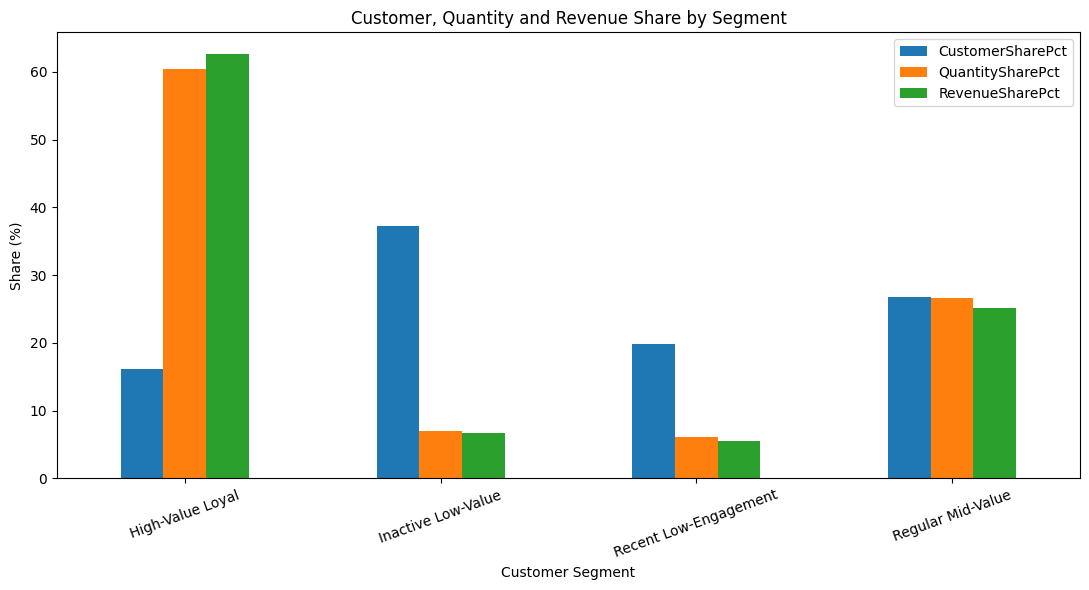

In [68]:
share_comparison = segment_business[
    ["CustomerSharePct", "QuantitySharePct", "RevenueSharePct"]
].copy()

share_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Customer, Quantity and Revenue Share by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Share (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [69]:
rfm.to_csv(
    "../outputs/customer_segments.csv",
    index=False
)

In [70]:
segment_business.reset_index().to_csv(
    "../outputs/segment_business_summary.csv",
    index=False
)

In [71]:
segment_strategy_summary.to_csv(
    "../outputs/segment_strategy_summary.csv",
    index=False
)